## BACKTESTING CON VENTANA MÓVIL Y REBALANCEO — UNIVERSO DIVERSIFICADO

Versión del backtest out-of-sample (Fase 9) para el universo de 44 activos repartidos en 11 sectores. Tiene un interruptor `UNIVERSE` para correr exactamente el mismo código sobre el universo original de 20 activos y comparar ambos en igualdad de condiciones.

### Cómo funciona (resumen)
En cada fecha de rebalanceo se estiman `mu` y la covarianza **solo con los últimos `ESTIMATION_WINDOW` días anteriores**, se optimiza, y esos pesos se mantienen hasta el siguiente rebalanceo. Nunca se usa información posterior a la decisión.

### Qué mejora respecto al `08_backtesting_rebalanceo` anterior
- **Comprar y mantener dentro de cada periodo.** Antes los pesos se aplicaban como si se reajustaran todos los días sin costo. Ahora cada periodo se simula con pesos que se desvían (derivan) según el precio, como en la realidad.
- **Costo sobre la rotación real.** El turnover se mide contra los pesos *ya desviados* que tiene el portafolio al llegar el rebalanceo, no contra los pesos objetivo anteriores.
- **Equal Weight rebalanceado con el mismo costo.** Antes Equal Weight era comprar y mantener sin costo, lo que lo favorecía. Se incluyen las dos versiones para ver cuánto pesa eso.
- **Respaldo de mínima volatilidad** cuando Max Sharpe no tiene solución (ningún activo con `mu` mayor que la tasa libre de riesgo).
- **Métricas de diversificación**: número efectivo de activos y composición por sector a lo largo del tiempo.

Por estos cambios, **los números no son comparables uno a uno con los del `08` original.**

Importación de librerías

In [1]:
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

from pypfopt.expected_returns import mean_historical_return
from pypfopt.risk_models import CovarianceShrinkage
from pypfopt.efficient_frontier import EfficientFrontier

warnings.filterwarnings("ignore", category=UserWarning)


In [2]:
# ============================================================
# CONFIGURACIÓN
# ============================================================

UNIVERSE = "diversified"   # "diversified" (44 activos) o "original" (20 activos)

ESTIMATION_WINDOW = 504    # ~2 años de datos para estimar mu y covarianza
REBALANCE_FREQ = 63        # rebalanceo trimestral (~63 días hábiles)

RISK_FREE_RATE = 0.02
TRANSACTION_COST = 0.001   # 10 puntos base por unidad de rotación (ajustable)
MIN_WEIGHT = 0.01          # cota mínima por activo en las estrategias optimizadas (0 = sin cota mínima)

benchmark = "^GSPC"

# Estrategias optimizadas: nombre -> (tipo, cota máxima por activo)
STRATEGIES = {
    "Markowitz Max Sharpe (max15%)": ("max_sharpe", 0.15),
    "Markowitz Max Sharpe (max10%)": ("max_sharpe", 0.10),
    "Markowitz Min Vol (max15%)":    ("min_volatility", 0.15),
    "Equal Weight (rebalanceado)":   ("equal_weight", None),
}

PROJECT_ROOT = Path.cwd().parent

data_folder = "processed_diversified" if UNIVERSE == "diversified" else "processed"
DATA_DIR = PROJECT_ROOT / "data" / data_folder

RUN_TAG = f"min{MIN_WEIGHT:g}_est{ESTIMATION_WINDOW}_reb{REBALANCE_FREQ}"
RESULTS_DIR = PROJECT_ROOT / "results" / f"backtesting_rebalanceo_{UNIVERSE}_{RUN_TAG}"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

PRICES_FILE = DATA_DIR / "adjusted_prices.csv"
RETURNS_FILE = DATA_DIR / "daily_returns.csv"
SECTOR_MAP_FILE = DATA_DIR / "sector_map.csv"

print("Universo:", UNIVERSE, "| datos en:", DATA_DIR)
print("Resultados en:", RESULTS_DIR)


Universo: diversified | datos en: c:\Users\ofeli\Documents\GitHub\Portafolio_investigacion\data\processed_diversified
Resultados en: c:\Users\ofeli\Documents\GitHub\Portafolio_investigacion\results\backtesting_rebalanceo_diversified_min0.01_est504_reb63


## Carga de datos

In [3]:
prices = pd.read_csv(PRICES_FILE, index_col=0, parse_dates=True)
returns = pd.read_csv(RETURNS_FILE, index_col=0, parse_dates=True)

returns_clean = returns.dropna(how="all")
prices_clean = prices.loc[returns_clean.index]

asset_prices = prices_clean.drop(columns=[benchmark])
asset_returns = returns_clean.drop(columns=[benchmark])

if SECTOR_MAP_FILE.exists():
    sector_map = pd.read_csv(SECTOR_MAP_FILE)
    ticker_to_sector = dict(zip(sector_map["ticker"], sector_map["sector"]))
else:
    ticker_to_sector = {}   # el universo original no tiene mapeo de sectores

n_assets_loaded = asset_prices.shape[1]
for name, (strategy, max_weight) in STRATEGIES.items():
    if max_weight is not None and max_weight * n_assets_loaded < 1:
        print(f"AVISO: '{name}' es infactible: {n_assets_loaded} activos x {max_weight:.0%} = {n_assets_loaded * max_weight:.0%} < 100%")

print("Activos:", asset_prices.shape[1])
print("Periodo:", asset_prices.index.min().date(), "→", asset_prices.index.max().date())
print("Primer rebalanceo (inicio del periodo out-of-sample):", asset_prices.index[ESTIMATION_WINDOW].date())


Activos: 44
Periodo: 2018-01-03 → 2026-09-30
Primer rebalanceo (inicio del periodo out-of-sample): 2020-01-06


## Funciones del backtest

`optimize_weights` calcula los pesos objetivo con información anterior. `rolling_backtest` recorre el tiempo: en cada fecha de rebalanceo decide, paga el costo de mover el portafolio desde los pesos desviados que tiene, y simula el periodo comprando y manteniendo.

In [4]:
def optimize_weights(strategy, train_prices, max_weight):
    """Pesos objetivo usando solo train_prices. Devuelve (pesos, usó_respaldo)."""

    mu = mean_historical_return(train_prices)
    S = CovarianceShrinkage(train_prices).ledoit_wolf()

    def build():
        ef = EfficientFrontier(mu, S, weight_bounds=(0, max_weight))
        if MIN_WEIGHT > 0:
            ef.add_constraint(lambda w: w >= MIN_WEIGHT)
        return ef

    used_fallback = False

    if strategy == "max_sharpe":
        try:
            ef = build()
            ef.max_sharpe(risk_free_rate=RISK_FREE_RATE)
        except Exception:
            ef = build()
            ef.min_volatility()
            used_fallback = True
    else:
        ef = build()
        ef.min_volatility()

    return pd.Series(ef.clean_weights()), used_fallback


def rolling_backtest(prices, returns, strategy, max_weight=None):

    dates = prices.index
    rebalance_points = range(ESTIMATION_WINDOW, len(dates), REBALANCE_FREQ)

    daily_parts = []
    weights_history = {}
    turnover_rows = []
    fallback_dates = []

    held_weights = pd.Series(0.0, index=prices.columns)   # pesos ya desviados por los precios

    for start_idx in rebalance_points:

        end_idx = min(start_idx + REBALANCE_FREQ, len(dates))
        hold = returns.iloc[start_idx:end_idx].fillna(0)

        if hold.empty:
            break

        # --- Decisión: solo con datos anteriores a start_idx ---
        train_prices = prices.iloc[start_idx - ESTIMATION_WINDOW:start_idx]
        complete_cols = train_prices.columns[train_prices.notna().all()]

        if strategy == "equal_weight":
            w = pd.Series(1 / len(complete_cols), index=complete_cols)
        else:
            try:
                w, used_fallback = optimize_weights(strategy, train_prices[complete_cols], max_weight)
                if used_fallback:
                    fallback_dates.append(dates[start_idx])
            except Exception as e:
                # Si la optimización no tiene solución: se conservan los pesos actuales;
                # si todavía no hay (primer rebalanceo), se usa Equal Weight.
                if held_weights.sum() > 0:
                    print(f"  Optimización falló en {dates[start_idx].date()} ({type(e).__name__}) - se conservan los pesos actuales")
                    w = held_weights[held_weights > 0]
                else:
                    print(f"  Optimización falló en {dates[start_idx].date()} ({type(e).__name__}) - se usa Equal Weight")
                    w = pd.Series(1 / len(complete_cols), index=complete_cols)
                fallback_dates.append(dates[start_idx])

        w = w.reindex(prices.columns).fillna(0)
        w = w / w.sum()

        # --- Costo: rotación real contra los pesos desviados ---
        turnover = (w - held_weights).abs().sum()
        cost = turnover * TRANSACTION_COST

        # --- Periodo de tenencia: comprar y mantener (los pesos se desvían con los precios) ---
        growth = (1 + hold).cumprod()
        value = (growth * w).sum(axis=1)               # valor de $1 invertido al inicio del periodo
        period_returns = value.pct_change()
        period_returns.iloc[0] = value.iloc[0] - 1 - cost   # el costo se descuenta el primer día

        held_weights = (growth.iloc[-1] * w) / value.iloc[-1]

        daily_parts.append(period_returns)
        weights_history[dates[start_idx]] = w
        turnover_rows.append({"Date": dates[start_idx], "turnover": turnover, "cost": cost})

    portfolio_returns = pd.concat(daily_parts)
    weights_df = pd.DataFrame(weights_history).T
    turnover_df = pd.DataFrame(turnover_rows).set_index("Date")

    return portfolio_returns, weights_df, turnover_df, fallback_dates


## Ejecución del backtest

Se resuelve una optimización por fecha de rebalanceo y por estrategia. Con 44 activos tarda unos minutos.

In [5]:
results = {}

for name, (strategy, max_weight) in STRATEGIES.items():
    print(f"Corriendo: {name}")
    results[name] = rolling_backtest(asset_prices, asset_returns, strategy, max_weight)

oos_start = min(r[0].index.min() for r in results.values())
oos_end = max(r[0].index.max() for r in results.values())

n_rebalances = len(next(iter(results.values()))[1])
print(f"\nRebalanceos: {n_rebalances} | periodo out-of-sample: {oos_start.date()} → {oos_end.date()}")


Corriendo: Markowitz Max Sharpe (max15%)
Corriendo: Markowitz Max Sharpe (max10%)
Corriendo: Markowitz Min Vol (max15%)
Corriendo: Equal Weight (rebalanceado)

Rebalanceos: 27 | periodo out-of-sample: 2020-01-06 → 2026-09-30


## Estrategias de referencia sobre el mismo periodo

- **S&P 500.**
- **Equal Weight comprar y mantener**: se compra 1/N al inicio y no se vuelve a tocar (sin rebalanceo ni costos más allá de la compra inicial). Se incluye para medir cuánto cambia el resultado al rebalancear Equal Weight.

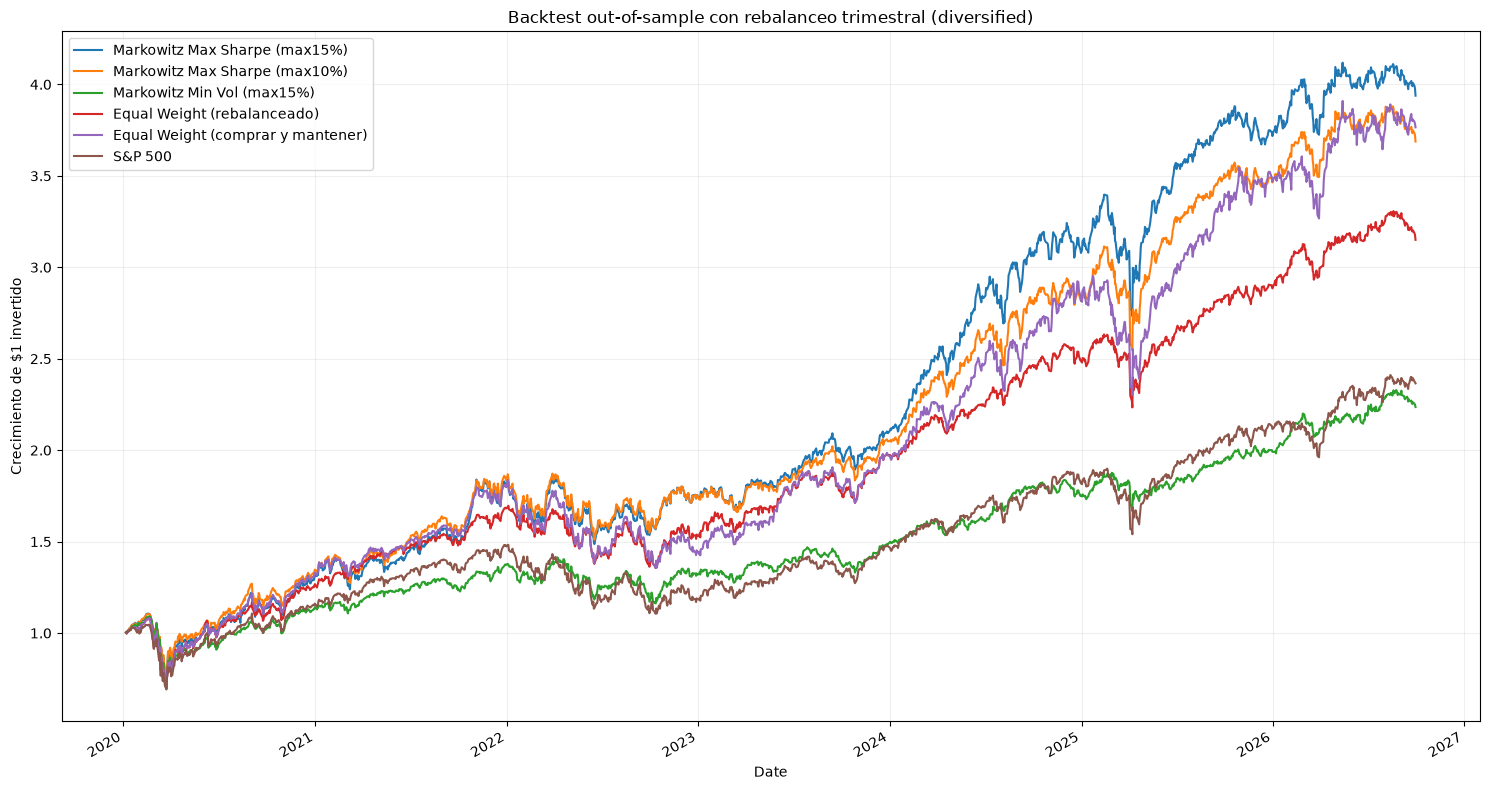

In [6]:
oos_returns = asset_returns.loc[oos_start:oos_end].fillna(0)

# Equal Weight comprar y mantener
growth_bh = (1 + oos_returns).cumprod()
value_bh = growth_bh.mean(axis=1)
returns_bh = value_bh.pct_change()
returns_bh.iloc[0] = value_bh.iloc[0] - 1 - TRANSACTION_COST   # compra inicial

daily_returns = pd.DataFrame({name: r[0] for name, r in results.items()})
daily_returns["Equal Weight (comprar y mantener)"] = returns_bh
daily_returns["S&P 500"] = returns_clean.loc[oos_start:oos_end, benchmark]
daily_returns = daily_returns.dropna()

comparison_oos = (1 + daily_returns).cumprod()

comparison_oos.plot(figsize=(15, 8), title=f"Backtest out-of-sample con rebalanceo trimestral ({UNIVERSE})")
plt.ylabel("Crecimiento de $1 invertido")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "01_backtest_rebalanceo.png", dpi=300, bbox_inches="tight")
plt.show()


## Métricas out-of-sample

Ninguna de estas estrategias usó información del futuro para decidir.

In [7]:
def annualized_metrics(daily: pd.Series, risk_free_rate: float = RISK_FREE_RATE) -> dict:
    cum = (1 + daily).cumprod()
    ann_return = daily.mean() * 252
    ann_vol = daily.std() * np.sqrt(252)
    max_dd = (cum / cum.cummax() - 1).min()
    return {
        "Retorno anualizado": ann_return,
        "Volatilidad anualizada": ann_vol,
        "Sharpe Ratio": (ann_return - risk_free_rate) / ann_vol,
        "Máximo Drawdown": max_dd,
        "Calmar Ratio": ann_return / abs(max_dd),
    }

summary_oos = pd.DataFrame({
    col: annualized_metrics(daily_returns[col]) for col in daily_returns.columns
}).T.sort_values("Sharpe Ratio", ascending=False)

summary_oos.round(4)


,Retorno anualizado,Volatilidad anualizada,Sharpe Ratio,Máximo Drawdown,Calmar Ratio
Markowitz Max Sharpe (max15%),0.2273,0.2150,0.9639,-0.3445,0.6597
Markowitz Max Sharpe (max10%),0.2154,0.2052,0.9522,-0.3235,0.6659
Equal Weight (comprar y mantener),0.2221,0.2219,0.9110,-0.3493,0.6358
Equal Weight (rebalanceado),0.1891,0.1906,0.8873,-0.3493,0.5414
Markowitz Min Vol (max15%),0.1347,0.1721,0.6663,-0.3624,0.3717
S&P 500,0.1487,0.2022,0.6365,-0.3392,0.4383


# Bootstrap por bloques
Remuestrea bloques de 21 días consecutivos (así conserva la dependencia temporal de los retornos) y usa los mismos días para todas las estrategias. Da un intervalo de confianza para cada Sharpe y para las diferencias entre estrategias.

SHARPE con intervalo de confianza (bootstrap por bloques de 21 días)


,Sharpe,IC 95% inferior,IC 95% superior
Markowitz Max Sharpe (max15%),0.964,0.295,1.812
Equal Weight (rebalanceado),0.887,0.159,1.756
S&P 500,0.636,-0.025,1.408


DIFERENCIAS entre estrategias (pareadas)


,Diferencia,IC 95% inferior,IC 95% superior,Prob. de que sea > 0,¿Distinguible del azar?
Markowitz Max Sharpe (max15%) − Equal Weight (rebalanceado),0.076657,-0.308743,0.437654,0.6535,no
Markowitz Max Sharpe (max15%) − S&P 500,0.327476,-0.032365,0.727342,0.961,no
Equal Weight (rebalanceado) − S&P 500,0.250819,0.033755,0.536896,0.989,sí


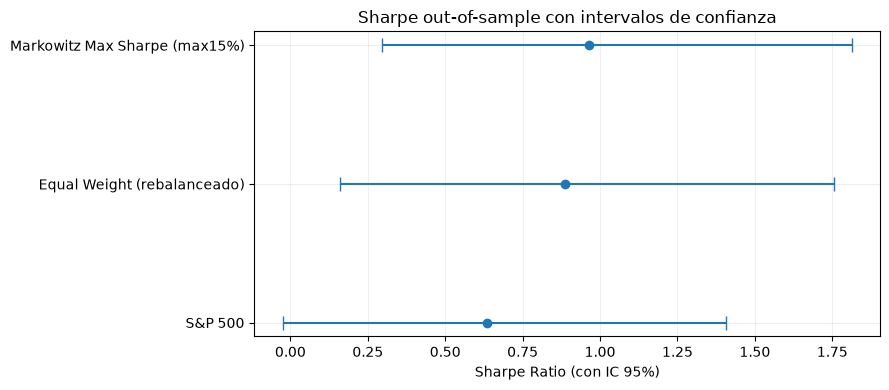

Bloque de 10 días


,Diferencia,IC 95% inferior,IC 95% superior,Prob. de que sea > 0,¿Distinguible del azar?
Markowitz Max Sharpe (max15%) − Equal Weight (rebalanceado),0.076657,-0.297847,0.428141,0.6595,no
Markowitz Max Sharpe (max15%) − S&P 500,0.327476,-0.019988,0.704126,0.965,no
Equal Weight (rebalanceado) − S&P 500,0.250819,0.034759,0.515435,0.989,sí


Bloque de 42 días


,Diferencia,IC 95% inferior,IC 95% superior,Prob. de que sea > 0,¿Distinguible del azar?
Markowitz Max Sharpe (max15%) − Equal Weight (rebalanceado),0.076657,-0.317718,0.402173,0.6465,no
Markowitz Max Sharpe (max15%) − S&P 500,0.327476,-0.046268,0.739761,0.955,no
Equal Weight (rebalanceado) − S&P 500,0.250819,0.054778,0.52797,0.994,sí


In [17]:
# ============================================================
# BLOQUE B — BOOTSTRAP POR BLOQUES: ¿la diferencia de Sharpe se distingue del azar?
# ============================================================
# Pégalo en 08_backtesting_rebalanceo_diversified, después de la celda "Métricas out-of-sample".

_missing = [n for n in ["daily_returns", "RISK_FREE_RATE"] if n not in globals()]
if _missing:
    raise NameError(f"Faltan definiciones del notebook: {_missing}.")


def block_bootstrap_sharpe(returns_df, pairs, block_len=21, n_boot=2000, seed=42, ci=95):
    """Remuestrea bloques de días consecutivos (conserva la dependencia temporal) y usa los MISMOS días
    para todas las estrategias (comparación pareada). Devuelve intervalos para el Sharpe de cada una
    y para la diferencia entre pares."""
    data = returns_df.dropna()
    cols = list(data.columns)
    R = data.values
    T = len(R)
    rng = np.random.default_rng(seed)

    n_blocks = int(np.ceil(T / block_len))
    offsets = np.arange(block_len)

    def sharpe_of(sample):
        return (sample.mean(axis=0) * 252 - RISK_FREE_RATE) / (sample.std(axis=0, ddof=1) * np.sqrt(252))

    boot = np.empty((n_boot, len(cols)))
    for b in range(n_boot):
        starts = rng.integers(0, T, n_blocks)
        idx = ((starts[:, None] + offsets) % T).ravel()[:T]     # bloques circulares
        boot[b] = sharpe_of(R[idx])

    point = sharpe_of(R)
    lo, hi = (100 - ci) / 2, 100 - (100 - ci) / 2

    sharpe_ci = pd.DataFrame({
        "Sharpe": point,
        f"IC {ci}% inferior": np.percentile(boot, lo, axis=0),
        f"IC {ci}% superior": np.percentile(boot, hi, axis=0),
    }, index=cols)

    rows = {}
    for a, b_ in pairs:
        i, j = cols.index(a), cols.index(b_)
        d = boot[:, i] - boot[:, j]
        rows[f"{a} − {b_}"] = {
            "Diferencia": point[i] - point[j],
            f"IC {ci}% inferior": np.percentile(d, lo),
            f"IC {ci}% superior": np.percentile(d, hi),
            "Prob. de que sea > 0": (d > 0).mean(),
            "¿Distinguible del azar?": "sí" if (np.percentile(d, lo) > 0 or np.percentile(d, hi) < 0) else "no",
        }
    return sharpe_ci, pd.DataFrame(rows).T


# --- Ejecución: ajusta los nombres si tus estrategias se llaman distinto ---
BOOT_COLS = ["Markowitz Max Sharpe (max15%)", "Equal Weight (rebalanceado)", "S&P 500"]
BOOT_PAIRS = [
    ("Markowitz Max Sharpe (max15%)", "Equal Weight (rebalanceado)"),
    ("Markowitz Max Sharpe (max15%)", "S&P 500"),
    ("Equal Weight (rebalanceado)", "S&P 500"),
]

sharpe_ci, diff_ci = block_bootstrap_sharpe(daily_returns[BOOT_COLS], BOOT_PAIRS, block_len=21, n_boot=2000)

print("SHARPE con intervalo de confianza (bootstrap por bloques de 21 días)")
display(sharpe_ci.round(3))
print("DIFERENCIAS entre estrategias (pareadas)")
display(diff_ci.round(3))

# Gráfica: intervalos de confianza del Sharpe
fig, ax = plt.subplots(figsize=(9, 4))
ypos = np.arange(len(sharpe_ci))[::-1]
lo_col, hi_col = sharpe_ci.columns[1], sharpe_ci.columns[2]
ax.errorbar(sharpe_ci["Sharpe"], ypos,
            xerr=[sharpe_ci["Sharpe"] - sharpe_ci[lo_col], sharpe_ci[hi_col] - sharpe_ci["Sharpe"]],
            fmt="o", capsize=5)
ax.set_yticks(ypos)
ax.set_yticklabels(sharpe_ci.index)
ax.set_xlabel("Sharpe Ratio (con IC 95%)")
ax.set_title("Sharpe out-of-sample con intervalos de confianza")
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()



# Prueba de robustez: repite con otro tamaño de bloque (10 y 42 días) y compara las conclusiones
for L in (10, 42):
    _, d = block_bootstrap_sharpe(daily_returns[BOOT_COLS], BOOT_PAIRS, block_len=L)
    print("Bloque de", L, "días"); display(d.round(3))


# SENSIBILIDAD
Repite el backtest completo con otra cota mínima, ventana de estimación o frecuencia de rebalanceo. Evalúa todas las configuraciones sobre el mismo periodo, el más corto en común, porque una ventana de estimación más larga empieza a operar más tarde y compararlas en periodos distintos sería injusto. Al terminar, deja tus parámetros como estaban.

Config 'sin mínimo' {'MIN_WEIGHT': 0}: 0.1 min
Config '0.5%' {'MIN_WEIGHT': 0.005}: 0.1 min
Config '1%' {'MIN_WEIGHT': 0.01}: 0.1 min
Periodo común de evaluación: 2020-01-06 → 2026-09-30


,Markowitz Max Sharpe (max15%),Equal Weight (rebalanceado),S&P 500,Markowitz Max Sharpe (max15%) − Equal Weight
sin mínimo,0.913,0.887,0.636,0.025
0.5%,0.926,0.887,0.636,0.039
1%,0.964,0.887,0.636,0.077


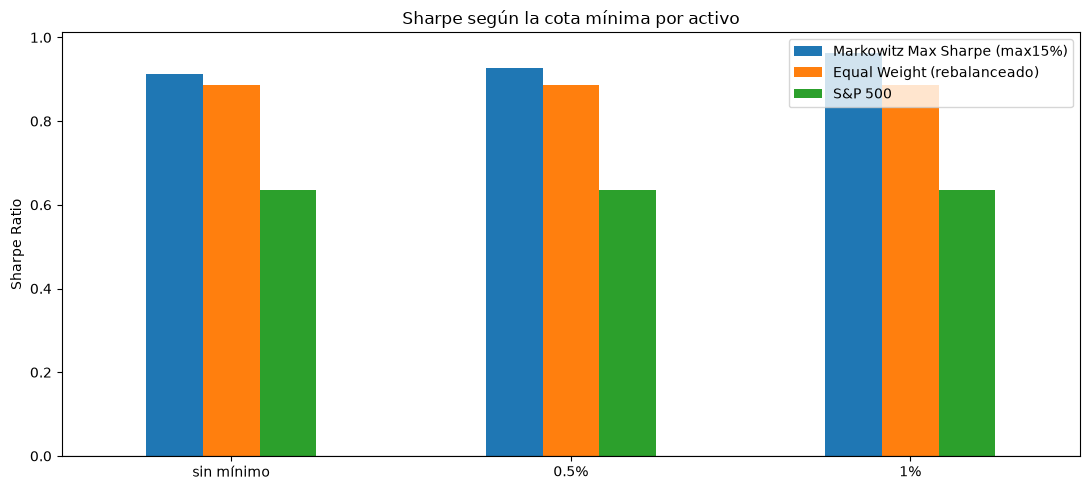

Config '1 año' {'ESTIMATION_WINDOW': 252}: 0.1 min
Config '2 años' {'ESTIMATION_WINDOW': 504}: 0.1 min
Config '3 años' {'ESTIMATION_WINDOW': 756}: 0.1 min
Periodo común de evaluación: 2021-01-05 → 2026-09-30


,Markowitz Max Sharpe (max15%),Equal Weight (rebalanceado),S&P 500,Markowitz Max Sharpe (max15%) − Equal Weight
1 año,1.106,1.067,0.731,0.039
2 años,1.084,1.067,0.731,0.017
3 años,0.963,1.066,0.731,-0.103


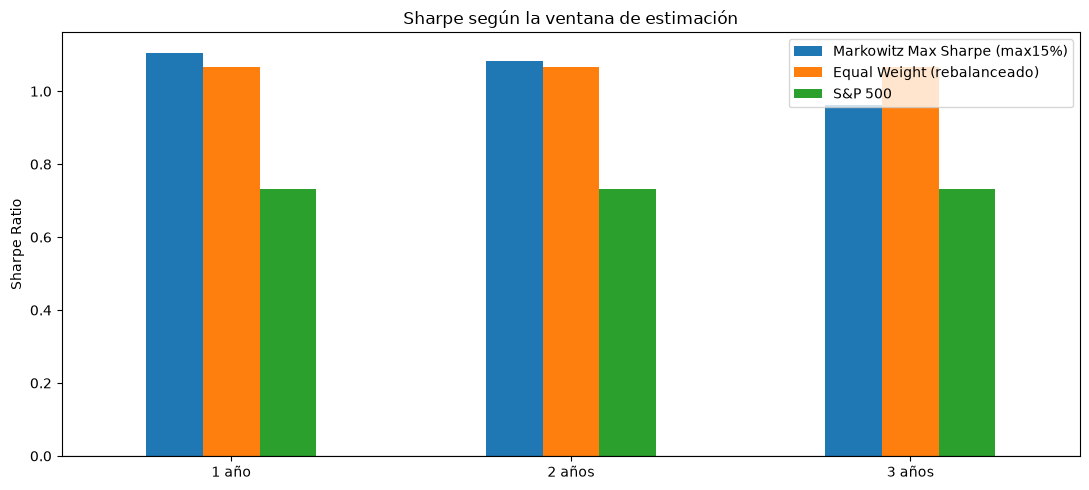

Config 'mensual' {'REBALANCE_FREQ': 21}: 0.3 min
Config 'trimestral' {'REBALANCE_FREQ': 63}: 0.1 min
Config 'semestral' {'REBALANCE_FREQ': 126}: 0.0 min
Periodo común de evaluación: 2020-01-06 → 2026-09-30


,Markowitz Max Sharpe (max15%),Equal Weight (rebalanceado),S&P 500,Markowitz Max Sharpe (max15%) − Equal Weight
mensual,1.038,0.880,0.636,0.158
trimestral,0.964,0.887,0.636,0.077
semestral,0.975,0.908,0.636,0.066


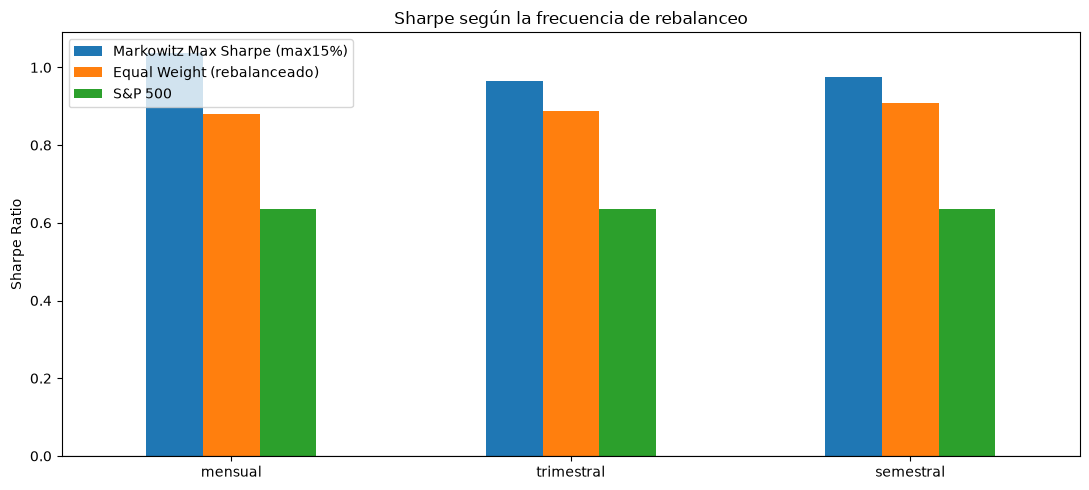

In [16]:
# ============================================================
# BLOQUE A — SENSIBILIDAD DEL BACKTEST A SUS PARÁMETROS
# (cota mínima, ventana de estimación, frecuencia de rebalanceo)
# ============================================================
# Pégalo en 08_backtesting_rebalanceo_diversified, después de la celda "Métricas out-of-sample".
# Cada configuración repite el backtest completo, así que tarda: empieza con las pruebas cortas.

import time

_PARAMS = ["ESTIMATION_WINDOW", "REBALANCE_FREQ", "TRANSACTION_COST", "MIN_WEIGHT"]
_missing = [n for n in _PARAMS + ["rolling_backtest", "STRATEGIES", "asset_prices", "asset_returns",
                                  "returns_clean", "benchmark", "annualized_metrics"] if n not in globals()]
if _missing:
    raise NameError(f"Faltan definiciones del notebook: {_missing}. Corre antes el notebook hasta la celda de métricas.")

EW_NAME = "Equal Weight (rebalanceado)"


def run_config(overrides, names):
    """Corre el backtest con parámetros temporalmente distintos; devuelve los retornos diarios por estrategia."""
    saved = {k: globals()[k] for k in _PARAMS}
    try:
        globals().update(overrides)
        out = {}
        for name in names:
            strategy, max_weight = STRATEGIES[name]
            out[name] = rolling_backtest(asset_prices, asset_returns, strategy, max_weight)[0]
        return pd.DataFrame(out)
    finally:
        globals().update(saved)      # los parámetros del notebook quedan como estaban


def compare_configs(configs, names=("Markowitz Max Sharpe (max15%)", EW_NAME)):
    """configs: {etiqueta: {parametro: valor}}. Todas se evalúan sobre el MISMO periodo (el más corto en común),
    porque una ventana de estimación más larga empieza a operar más tarde."""
    names = list(names)
    runs = {}
    for label, overrides in configs.items():
        t0 = time.time()
        runs[label] = run_config(overrides, names)
        print(f"Config '{label}' {overrides}: {(time.time() - t0) / 60:.1f} min")

    start = max(df.index.min() for df in runs.values())
    end = min(df.index.max() for df in runs.values())
    sp = returns_clean.loc[start:end, benchmark].dropna()
    print(f"Periodo común de evaluación: {start.date()} → {end.date()}")

    sharpe, metrics = {}, {}
    for label, df in runs.items():
        d = df.loc[start:end]
        sharpe[label] = {n: annualized_metrics(d[n].dropna())["Sharpe Ratio"] for n in names}
        sharpe[label]["S&P 500"] = annualized_metrics(sp)["Sharpe Ratio"]
        for n in names:
            metrics[(label, n)] = annualized_metrics(d[n].dropna())

    sharpe = pd.DataFrame(sharpe).T
    if EW_NAME in names:
        for n in names:
            if n != EW_NAME:
                sharpe[f"{n} − Equal Weight"] = sharpe[n] - sharpe[EW_NAME]
    metrics = pd.DataFrame(metrics).T
    return {"sharpe": sharpe, "metrics": metrics, "periodo": (start, end), "runs": runs}


def plot_sensitivity(res, title):
    cols = [c for c in res["sharpe"].columns if "−" not in c]
    ax = res["sharpe"][cols].plot(kind="bar", figsize=(11, 5), title=title)
    ax.set_ylabel("Sharpe Ratio")
    ax.axhline(0, color="black", linewidth=0.8)
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()


# ---------------- Experimentos (cada uno es independiente; corre los que quieras) ----------------

# 1) Cota mínima por activo: ¿cuánto pesa esa restricción?  (el más importante; tarda unos minutos)
res_min = compare_configs({"sin mínimo": {"MIN_WEIGHT": 0}, "0.5%": {"MIN_WEIGHT": 0.005}, "1%": {"MIN_WEIGHT": 0.01}})
display(res_min["sharpe"].round(3)); plot_sensitivity(res_min, "Sharpe según la cota mínima por activo")

# 2) Ventana de estimación (en días hábiles: 252 ≈ 1 año)
res_win = compare_configs({"1 año": {"ESTIMATION_WINDOW": 252}, "2 años": {"ESTIMATION_WINDOW": 504}, "3 años": {"ESTIMATION_WINDOW": 756}})
display(res_win["sharpe"].round(3)); plot_sensitivity(res_win, "Sharpe según la ventana de estimación")

# 3) Frecuencia de rebalanceo (21 ≈ mensual, 63 ≈ trimestral, 126 ≈ semestral). El mensual hace muchas optimizaciones.
res_reb = compare_configs({"mensual": {"REBALANCE_FREQ": 21}, "trimestral": {"REBALANCE_FREQ": 63}, "semestral": {"REBALANCE_FREQ": 126}})
display(res_reb["sharpe"].round(3)); plot_sensitivity(res_reb, "Sharpe según la frecuencia de rebalanceo")

# Para ver todas las métricas de una corrida:  res_min["metrics"].round(3)

## Rotación, costos y respaldos

Cuánto hay que mover el portafolio en cada rebalanceo. Rotación alta implica más costos y menor viabilidad práctica. También se cuenta cuántas veces Max Sharpe tuvo que usar el respaldo de mínima volatilidad.

,Rotación promedio por rebalanceo,Costo total acumulado,Rebalanceos con respaldo
Markowitz Max Sharpe (max15%),0.4209,0.0119,0
Markowitz Max Sharpe (max10%),0.3806,0.0109,0
Markowitz Min Vol (max15%),0.2144,0.0066,0
Equal Weight (rebalanceado),0.0997,0.0036,0


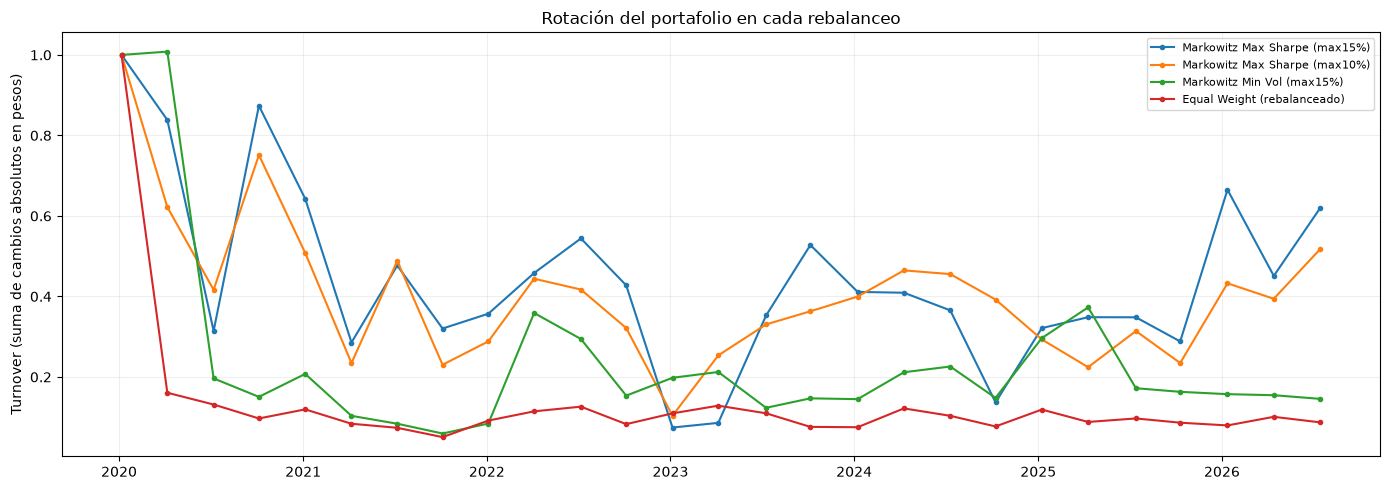

In [10]:
optimized = [n for n, (s, _) in STRATEGIES.items() if s != "equal_weight"]

cost_summary = pd.DataFrame({
    name: {
        "Rotación promedio por rebalanceo": results[name][2]["turnover"].iloc[1:].mean(),   # sin contar la compra inicial
        "Costo total acumulado": results[name][2]["cost"].sum(),
        "Rebalanceos con respaldo": len(results[name][3]),
    }
    for name in results
}).T
cost_summary["Rebalanceos con respaldo"] = cost_summary["Rebalanceos con respaldo"].astype(int)

display(cost_summary.round(4))

fig, ax = plt.subplots(figsize=(14, 5))
for name in results:
    ax.plot(results[name][2].index, results[name][2]["turnover"], marker="o", markersize=3, label=name)
ax.set_title("Rotación del portafolio en cada rebalanceo")
ax.set_ylabel("Turnover (suma de cambios absolutos en pesos)")
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "02_turnover.png", dpi=300, bbox_inches="tight")
plt.show()


# COSTOS
¿Cambia la conclusión si operar es más caro?

Sharpe según el costo de transacción (el notebook usa 10 pb)


,Markowitz Max Sharpe (max15%),Markowitz Max Sharpe (max10%),Markowitz Min Vol (max15%),Equal Weight (rebalanceado),S&P 500 (sin costo)
costo por unidad de rotación,,,,,
0 pb,0.972,0.960,0.672,0.890,0.636
10 pb,0.964,0.952,0.666,0.887,0.636
25 pb,0.952,0.941,0.658,0.883,0.636
50 pb,0.931,0.921,0.644,0.876,0.636


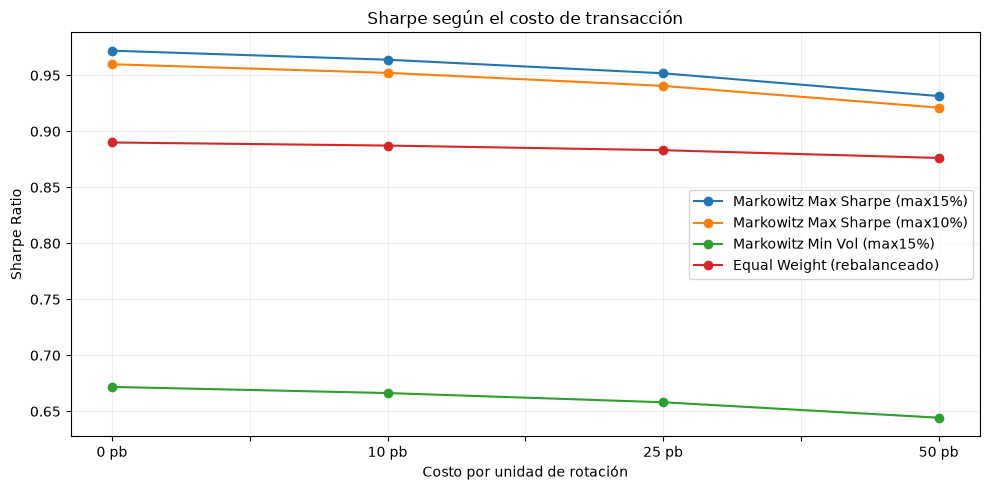

Config 'mensual, 10 pb' {'REBALANCE_FREQ': 21, 'TRANSACTION_COST': 0.001}: 0.1 min
Config 'mensual, 25 pb' {'REBALANCE_FREQ': 21, 'TRANSACTION_COST': 0.0025}: 0.1 min
Config 'mensual, 50 pb' {'REBALANCE_FREQ': 21, 'TRANSACTION_COST': 0.005}: 0.1 min
Periodo común de evaluación: 2020-01-06 → 2026-09-30


,Markowitz Max Sharpe (max15%),Equal Weight (rebalanceado),S&P 500,Markowitz Max Sharpe (max15%) − Equal Weight
"mensual, 10 pb",1.038,0.880,0.636,0.158
"mensual, 25 pb",1.015,0.874,0.636,0.141
"mensual, 50 pb",0.977,0.864,0.636,0.113


: 

In [ ]:
# ============================================================
# BLOQUE C — SENSIBILIDAD A LOS COSTOS DE TRANSACCIÓN (sin reoptimizar)
# ============================================================

_missing = [n for n in ["results", "annualized_metrics", "returns_clean", "benchmark", "TRANSACTION_COST"] if n not in globals()]
if _missing:
    raise NameError(f"Faltan definiciones del notebook: {_missing}.")


def cost_sensitivity(costs=(0, 0.001, 0.0025, 0.005)):
    table = {}
    for name, (r, weights, turnover_df, fallbacks) in results.items():
        gross = r + turnover_df["cost"].reindex(r.index).fillna(0)           # se quita el costo base
        turnover = turnover_df["turnover"].reindex(r.index).fillna(0)
        for c in costs:
            net = gross - turnover * c                                       # se aplica el costo nuevo
            table.setdefault(c, {})[name] = annualized_metrics(net.dropna())["Sharpe Ratio"]

    out = pd.DataFrame(table).T
    any_r = next(iter(results.values()))[0]
    sp = returns_clean.loc[any_r.index, benchmark].dropna()
    out["S&P 500 (sin costo)"] = annualized_metrics(sp)["Sharpe Ratio"]
    out.index = [f"{c * 1e4:.0f} pb" for c in costs]
    out.index.name = "costo por unidad de rotación"
    return out


costs_table = cost_sensitivity()
print(f"Sharpe según el costo de transacción (el notebook usa {TRANSACTION_COST * 1e4:.0f} pb)")
display(costs_table.round(3))

costs_table.drop(columns="S&P 500 (sin costo)").plot(marker="o", figsize=(10, 5),
                                                    title="Sharpe según el costo de transacción")
plt.ylabel("Sharpe Ratio")
plt.xlabel("Costo por unidad de rotación")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

res_cost_mensual = compare_configs({"mensual, 10 pb": {"REBALANCE_FREQ": 21, "TRANSACTION_COST": 0.001},
                                    "mensual, 25 pb": {"REBALANCE_FREQ": 21, "TRANSACTION_COST": 0.0025},
                                    "mensual, 50 pb": {"REBALANCE_FREQ": 21, "TRANSACTION_COST": 0.005}})
display(res_cost_mensual["sharpe"].round(3))

## Concentración: número efectivo de activos

`1 / Σ w²` es el número de activos "equivalentes" con el mismo peso. Equal Weight con 44 activos da 44; un portafolio concentrado en 6 nombres da cerca de 6. Es la forma más directa de ver si Markowitz realmente reparte el riesgo o se concentra.

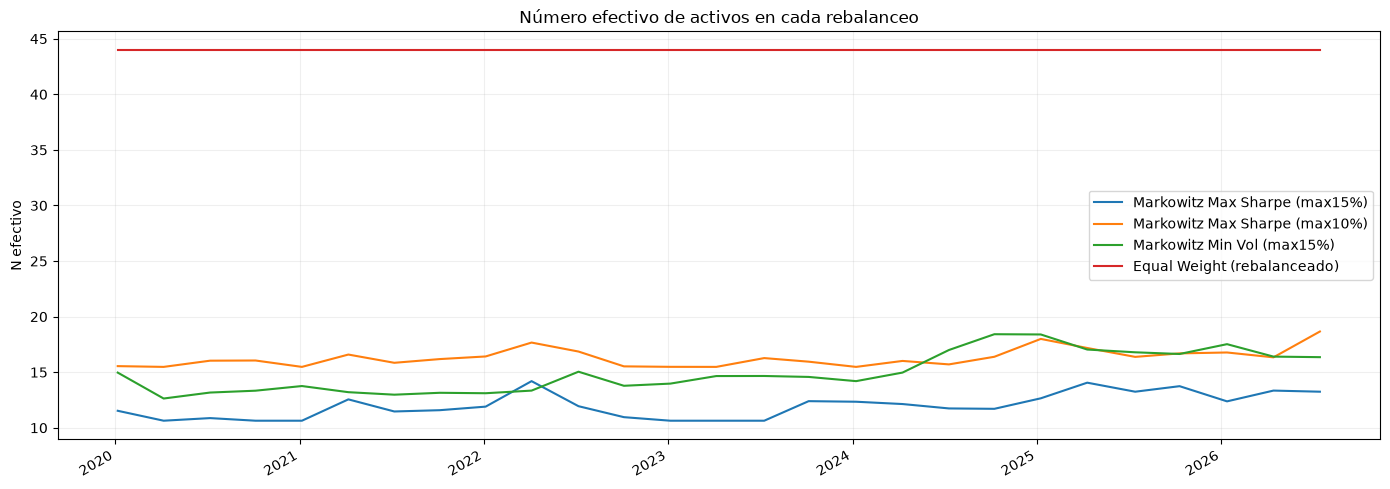

,N efectivo promedio
Markowitz Max Sharpe (max15%),12.0
Markowitz Max Sharpe (max10%),16.3
Markowitz Min Vol (max15%),15.0
Equal Weight (rebalanceado),44.0


In [12]:
effective_n = pd.DataFrame({
    name: 1 / (results[name][1] ** 2).sum(axis=1)
    for name in results
})

effective_n.plot(figsize=(14, 5), title="Número efectivo de activos en cada rebalanceo")
plt.ylabel("N efectivo")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "03_numero_efectivo_activos.png", dpi=300, bbox_inches="tight")
plt.show()

effective_n.mean().round(1).to_frame("N efectivo promedio")


## Composición por sector a lo largo del tiempo

Solo aplica al universo diversificado (el original no tiene mapeo de sectores). Muestra si Markowitz sigue concentrándose en pocos sectores aunque tenga 44 activos disponibles.

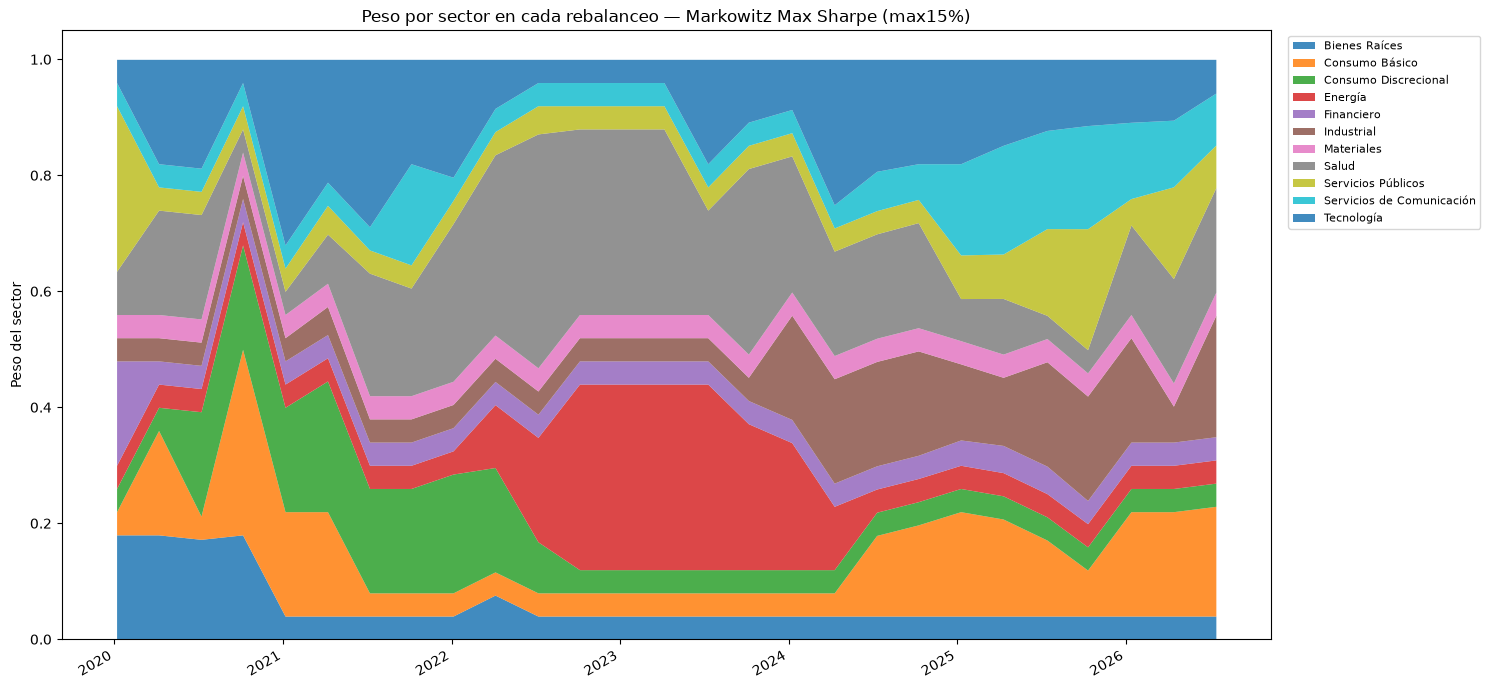

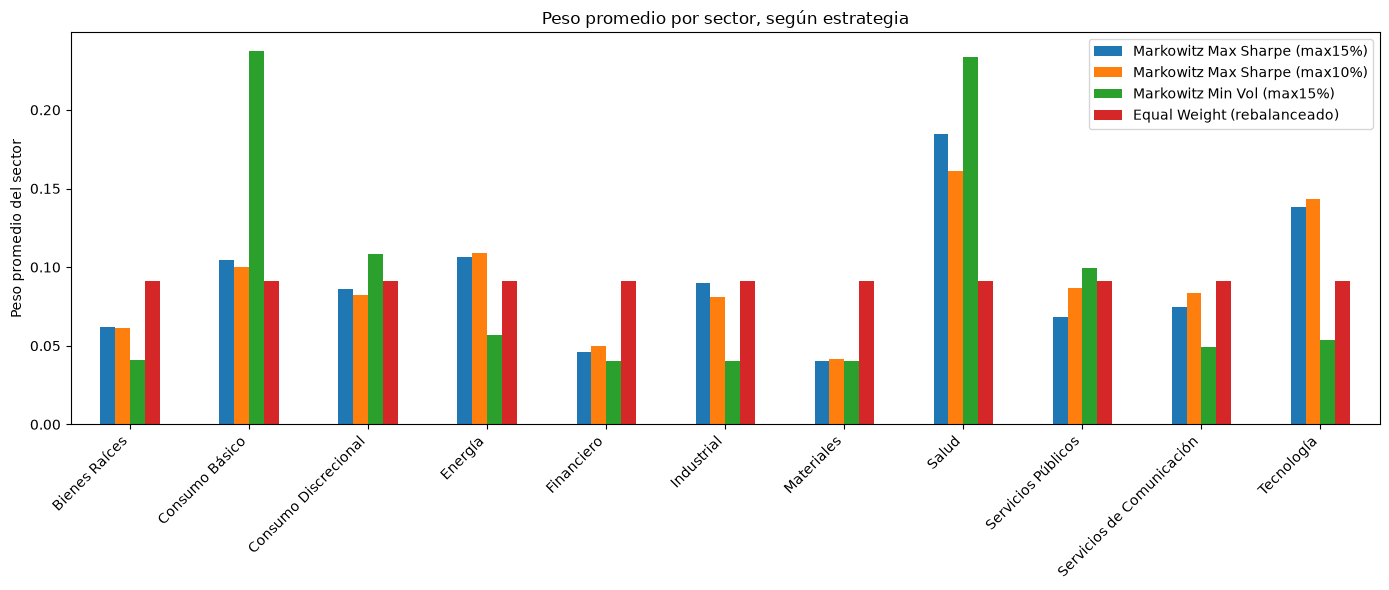

,Markowitz Max Sharpe (max15%),Markowitz Max Sharpe (max10%),Markowitz Min Vol (max15%),Equal Weight (rebalanceado)
Bienes Raíces,0.062,0.061,0.041,0.091
Consumo Básico,0.105,0.100,0.237,0.091
Consumo Discrecional,0.086,0.082,0.109,0.091
Energía,0.106,0.109,0.057,0.091
Financiero,0.046,0.050,0.041,0.091
Industrial,0.090,0.081,0.040,0.091
Materiales,0.040,0.042,0.040,0.091
Salud,0.184,0.161,0.233,0.091
Servicios Públicos,0.069,0.086,0.100,0.091
Servicios de Comunicación,0.075,0.083,0.049,0.091


In [13]:
if ticker_to_sector:

    def sector_weights(weights_df):
        return weights_df.T.groupby(lambda t: ticker_to_sector.get(t, "Otro")).sum().T

    focus = "Markowitz Max Sharpe (max15%)"
    sw = sector_weights(results[focus][1])

    fig, ax = plt.subplots(figsize=(15, 7))
    sw.plot(kind="area", stacked=True, ax=ax, alpha=0.85, linewidth=0)
    ax.set_title(f"Peso por sector en cada rebalanceo — {focus}")
    ax.set_ylabel("Peso del sector")
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "04_sectores_en_el_tiempo.png", dpi=300, bbox_inches="tight")
    plt.show()

    avg_sector = pd.DataFrame({name: sector_weights(results[name][1]).mean() for name in results}).fillna(0)
    avg_sector.plot(kind="bar", figsize=(14, 6), title="Peso promedio por sector, según estrategia")
    plt.ylabel("Peso promedio del sector")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / "05_sectores_promedio.png", dpi=300, bbox_inches="tight")
    plt.show()

    display(avg_sector.round(3))
else:
    print("Sin mapeo de sectores para este universo: se omite esta sección.")


## Comparación entre universos 

Si ya corriste este mismo notebook con el otro universo **y la misma configuración** (`MIN_WEIGHT`, ventana y frecuencia de rebalanceo, que forman parte del nombre de la carpeta), aquí se ponen lado a lado. El S&P 500 es el mismo en ambos, así que sirve de punto de referencia común.

In [14]:
other = "original" if UNIVERSE == "diversified" else "diversified"
other_file = PROJECT_ROOT / "results" / f"backtesting_rebalanceo_{other}_{RUN_TAG}" / "summary_oos.csv"

if other_file.exists():
    other_summary = pd.read_csv(other_file, index_col=0)

    side_by_side = pd.concat(
        {UNIVERSE: summary_oos["Sharpe Ratio"], other: other_summary["Sharpe Ratio"]},
        axis=1
    )
    print("SHARPE RATIO out-of-sample por universo")
    display(side_by_side.round(3))

    dd_side = pd.concat(
        {UNIVERSE: summary_oos["Máximo Drawdown"], other: other_summary["Máximo Drawdown"]},
        axis=1
    )
    print("MÁXIMO DRAWDOWN por universo")
    display(dd_side.round(3))
else:
    print("Aún no hay resultados del universo", other, "con esta configuración.")
    print("Corre este notebook con UNIVERSE =", repr(other), "para poder compararlos.")


Aún no hay resultados del universo original con esta configuración.
Corre este notebook con UNIVERSE = 'original' para poder compararlos.


## Cómo leer los resultados

- **Sharpe out-of-sample:** compara contra Equal Weight rebalanceado, que es la referencia justa para Markowitz.
- **N efectivo:** si Markowitz queda cerca del número de activos de Equal Weight, la cota mínima lo está forzando a parecerse a él; si cae a pocas unidades, se concentra.
- **Equal Weight comprar y mantener vs. rebalanceado:** la diferencia muestra el efecto de rebalancear (y del costo) sobre una estrategia que no estima nada.
- **Costos:** compara el costo acumulado con la diferencia de retorno entre estrategias, para ver si la fricción explica algo.

## Guardar resultados

In [15]:
comparison_oos.to_csv(RESULTS_DIR / "backtest_oos.csv")
summary_oos.to_csv(RESULTS_DIR / "summary_oos.csv")
cost_summary.to_csv(RESULTS_DIR / "costos_y_rotacion.csv")
effective_n.to_csv(RESULTS_DIR / "numero_efectivo_activos.csv")

for name in results:
    safe = name.replace(" ", "_").replace("(", "").replace(")", "").replace("%", "pct")
    results[name][1].to_csv(RESULTS_DIR / f"pesos_{safe}.csv")
    results[name][2].to_csv(RESULTS_DIR / f"turnover_{safe}.csv")

print("Resultados guardados en:", RESULTS_DIR)


Resultados guardados en: c:\Users\ofeli\Documents\GitHub\Portafolio_investigacion\results\backtesting_rebalanceo_diversified_min0.01_est504_reb63
